In [16]:
import matplotlib.pyplot as plt  
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42

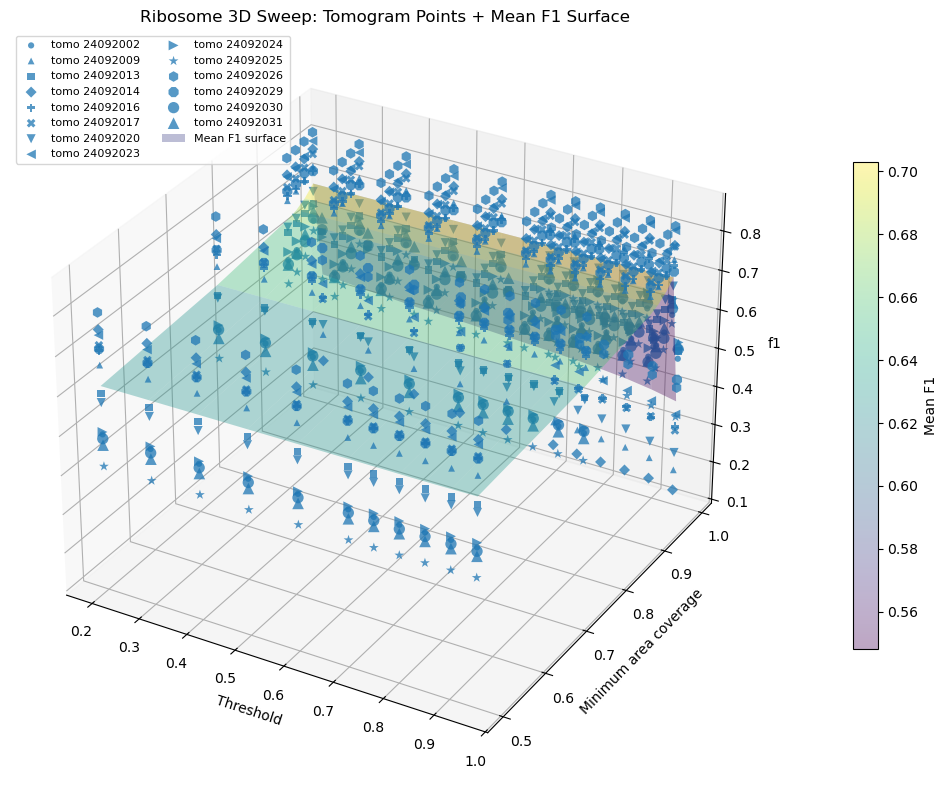

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path('./sweep_results/sweep_ribosome.csv')
df = pd.read_csv(csv_path)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot each tomogram with a distinct marker/size (same color).
tomo_ids = sorted(df['tomo_id'].unique())
markers = ['o', '^', 's', 'D', 'P', 'X', 'v', '<', '>', '*', 'h', '8']
size_levels = np.linspace(20, 70, len(tomo_ids)) if len(tomo_ids) > 1 else np.array([35.0])
for i, tomo_id in enumerate(tomo_ids):
    tomo_df = df[df['tomo_id'] == tomo_id]
    ax.scatter(
        tomo_df['thres'],
        tomo_df['thres2'],
        tomo_df['f1'],
        color='tab:blue',
        marker=markers[i % len(markers)],
        s=float(size_levels[i]),
        alpha=0.75,
        edgecolors='none',
        label=f'tomo {tomo_id}',
    )

# Mean surface: average F1 across tomograms for each (thres, thres2).
mean_grid = (
    df.groupby(['thres', 'thres2'], as_index=False)['f1']
    .mean()
    .rename(columns={'f1': 'mean_f1'})
)

surface_df = (
    mean_grid.pivot(index='thres2', columns='thres', values='mean_f1')
    .sort_index()
    .sort_index(axis=1)
)

X, Y = np.meshgrid(surface_df.columns.values, surface_df.index.values)
Z = surface_df.values

surf = ax.plot_surface(
    X, Y, Z,
    cmap='viridis',
    alpha=0.35,
    linewidth=0,
    antialiased=True,
    label='Mean F1 surface',
)
cbar = fig.colorbar(surf, ax=ax, shrink=0.65, pad=0.08)
cbar.set_label('Mean F1')

ax.set_title('Ribosome 3D Sweep: Tomogram Points + Mean F1 Surface')
ax.set_xlabel('Threshold')
ax.set_ylabel('Minimum area coverage')
ax.set_zlabel('f1')
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 1.0), fontsize=8, ncol=2)
fig.tight_layout()
plt.savefig('/home/feity/compare_release/deepETpicker/sweep_results/ribosome_3d_sweep.pdf')
plt.show()

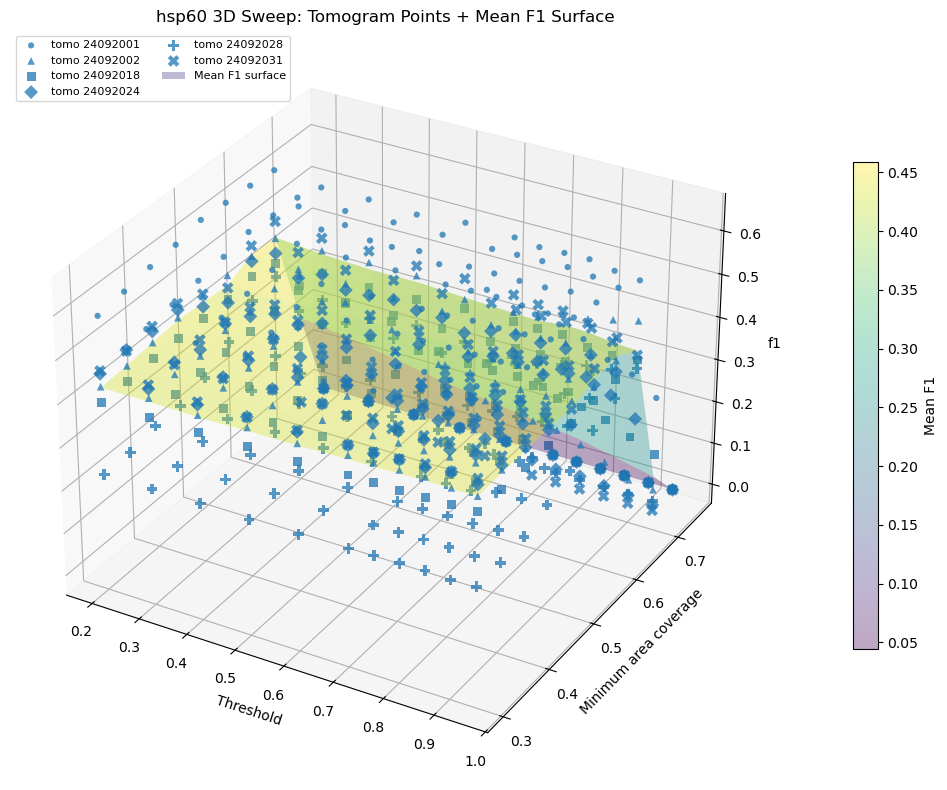

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = Path('./sweep_results/sweep_hsp60.csv')
df = pd.read_csv(csv_path)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot each tomogram with a distinct marker/size (same color).
tomo_ids = sorted(df['tomo_id'].unique())
markers = ['o', '^', 's', 'D', 'P', 'X', 'v', '<', '>', '*', 'h', '8']
size_levels = np.linspace(20, 70, len(tomo_ids)) if len(tomo_ids) > 1 else np.array([35.0])
for i, tomo_id in enumerate(tomo_ids):
    tomo_df = df[df['tomo_id'] == tomo_id]
    ax.scatter(
        tomo_df['thres'],
        tomo_df['thres2'],
        tomo_df['f1'],
        color='tab:blue',
        marker=markers[i % len(markers)],
        s=float(size_levels[i]),
        alpha=0.75,
        edgecolors='none',
        label=f'tomo {tomo_id}',
    )

# Mean surface: average F1 across tomograms for each (thres, thres2).
mean_grid = (
    df.groupby(['thres', 'thres2'], as_index=False)['f1']
    .mean()
    .rename(columns={'f1': 'mean_f1'})
)

surface_df = (
    mean_grid.pivot(index='thres2', columns='thres', values='mean_f1')
    .sort_index()
    .sort_index(axis=1)
)

X, Y = np.meshgrid(surface_df.columns.values, surface_df.index.values)
Z = surface_df.values

surf = ax.plot_surface(
    X, Y, Z,
    cmap='viridis',
    alpha=0.35,
    linewidth=0,
    antialiased=True,
    label='Mean F1 surface',
)
cbar = fig.colorbar(surf, ax=ax, shrink=0.65, pad=0.08)
cbar.set_label('Mean F1')

ax.set_title('hsp60 3D Sweep: Tomogram Points + Mean F1 Surface')
ax.set_xlabel('Threshold')
ax.set_ylabel('Minimum area coverage')
ax.set_zlabel('f1')
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 1.0), fontsize=8, ncol=2)
fig.tight_layout()
plt.savefig('/home/feity/compare_release/deepETpicker/sweep_results/hsp60_3d_sweep.pdf')
plt.show()